New EDA notebook for calculating feature importance


In [5]:
import os
import sys
from pathlib import Path


# Add project root to sys.path if running inside notebooks/
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

# Required for unpickling Categorical Naive Bayes
from src.models_common import ShiftedCategoricalNB

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score
from src.data_preprocessing import load_dataset, get_preprocessed_data, URL_FEATURES

In [4]:
df = pd.read_csv("../dataset/phishing.csv")

In [5]:
df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [6]:
df.describe()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
count,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,...,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000,11055.000000
mean,0.313795,-0.633198,0.738761,0.700588,0.741474,-0.734962,0.063953,0.250927,-0.336771,0.628584,...,0.613388,0.816915,0.061239,0.377114,0.287291,-0.483673,0.721574,0.344007,0.719584,0.113885
std,0.949534,0.766095,0.673998,0.713598,0.671011,0.678139,0.817518,0.911892,0.941629,0.777777,...,0.789818,0.576784,0.998168,0.926209,0.827733,0.875289,0.692369,0.569944,0.694437,0.993539
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,-1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,...,1.000000,1.000000,-1.000000,-1.000000,0.000000,-1.000000,1.000000,0.000000,1.000000,-1.000000
50%,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,0.000000,1.000000,-1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,0.000000,1.000000,1.000000
75%,1.000000,-1.000000,1.000000,1.000000,1.000000,-1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
def load_all_models(track="b"):
    models_dir = BASE_DIR / "models" / f"model_{track.lower()}"
    models = {}
    for file in models_dir.glob("*.joblib"):
        model_name = file.stem  # e.g., 'random_forest'
        models[model_name] = joblib.load(file)
    return models

# Load all Track A models
models_a = load_all_models("a")
print(models_a)
print("Available Track A models:", list(models_a.keys()))

{'logistic_regression': LogisticRegression(max_iter=1000, random_state=42), 'random_forest': RandomForestClassifier(n_estimators=150, random_state=42), 'gaussian_nb': GaussianNB(), 'decision_tree': DecisionTreeClassifier(criterion='entropy', random_state=42), 'categorical_nb': ShiftedCategoricalNB()}
Available Track A models: ['logistic_regression', 'random_forest', 'gaussian_nb', 'decision_tree', 'categorical_nb']


In [12]:
dt_model = models_a["decision_tree"]
rf_model = models_a["random_forest"]

In [9]:
output = df['Result']

In [10]:
df = df.drop(columns = "Result")

In [11]:
importances = dt_model.feature_importances_
feature_names = df.columns

feature_importance_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": importances}
).sort_values(by="Importance", ascending=False)
print("Decision Tree Feature Importance (Top 5:)")
print(feature_importance_df.head(5))

Decision Tree Feature Importance (Top 5:)
              Feature  Importance
7      SSLfinal_State    0.514710
13      URL_of_Anchor    0.165662
25        web_traffic    0.044804
14      Links_in_tags    0.041858
6   having_Sub_Domain    0.033163


In [13]:
importances = rf_model.feature_importances_
feature_names = df.columns

feature_importance_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": importances}
).sort_values(by="Importance", ascending=False)
print("Random Forest Feature Importance (Top 5:)")
print(feature_importance_df.head(5))

Random Forest Feature Importance (Top 5:)
              Feature  Importance
7      SSLfinal_State    0.331808
13      URL_of_Anchor    0.245089
25        web_traffic    0.073511
6   having_Sub_Domain    0.061539
14      Links_in_tags    0.043254


Decision Tree Test Accuracy : 97.01%
Random Forest Test Accuracy : 97.60%


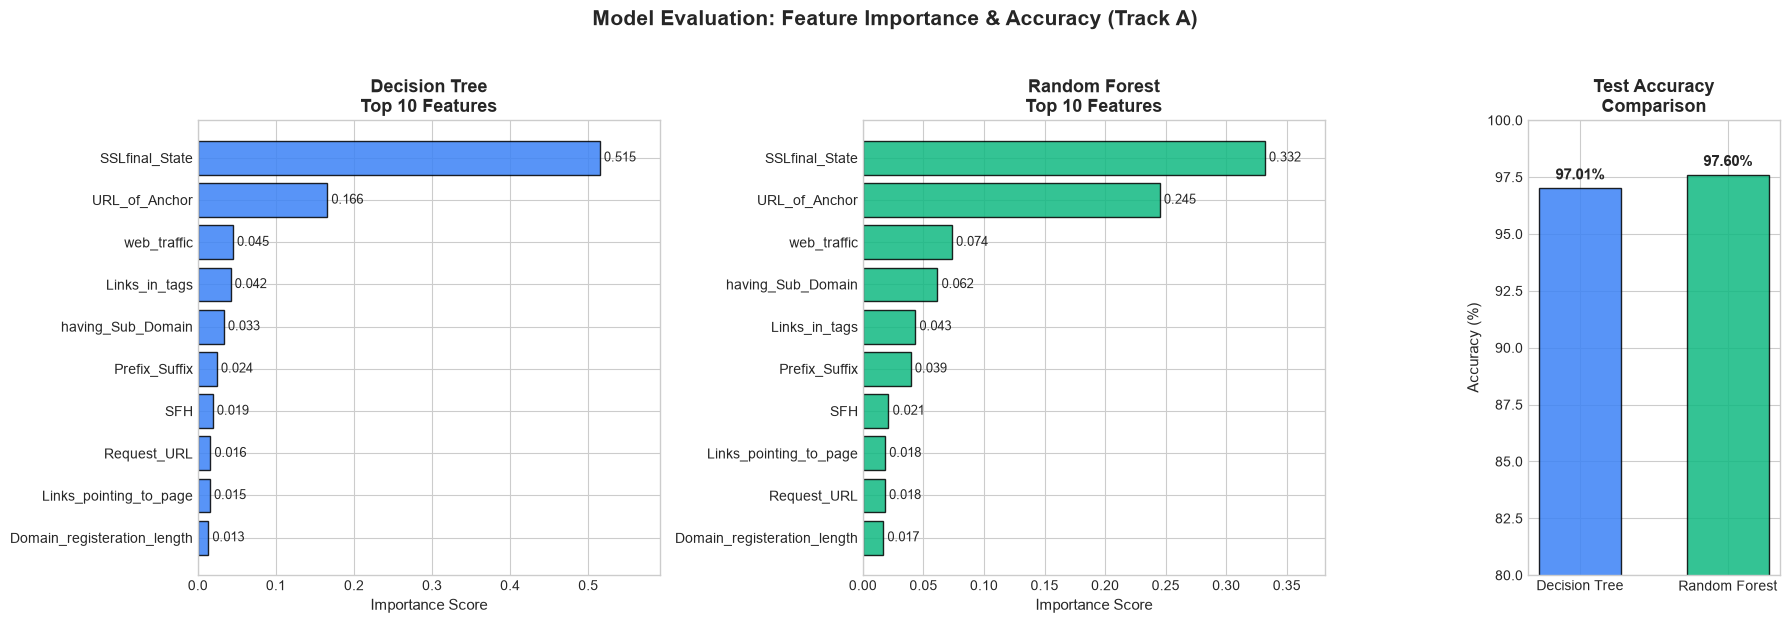

In [15]:
# ----------------------------------------------------
# 1. Compute Model Accuracy on Test Data
# ----------------------------------------------------
raw_df = load_dataset()
data = get_preprocessed_data(raw_df)
X_test = data['X_test_a']
y_test = data['y_test']

# Compute accuracy
dt_acc = accuracy_score(y_test, dt_model.predict(X_test))
rf_acc = accuracy_score(y_test, rf_model.predict(X_test))

print(f"Decision Tree Test Accuracy : {dt_acc * 100:.2f}%")
print(f"Random Forest Test Accuracy : {rf_acc * 100:.2f}%")

# ----------------------------------------------------
# 2. Extract Top 10 Feature Importances
# ----------------------------------------------------
TOP_N = 10
features = df.columns

# Decision Tree Top N
dt_df = (
    pd.DataFrame({"Feature": features, "Importance": dt_model.feature_importances_})
    .sort_values(by="Importance", ascending=True)  # Ascending so largest appears at top in barh
    .tail(TOP_N)
)

# Random Forest Top N
rf_df = (
    pd.DataFrame({"Feature": features, "Importance": rf_model.feature_importances_})
    .sort_values(by="Importance", ascending=True)
    .tail(TOP_N)
)

# ----------------------------------------------------
# 3. Plotting: Feature Importances & Accuracy Comparison
# ----------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2, ax3) = plt.subplots(
    1, 3, 
    figsize=(18, 6), 
    gridspec_kw={'width_ratios': [2.2, 2.2, 1.2]}
)

# [Plot 1] Decision Tree Feature Importance
bars_dt = ax1.barh(dt_df["Feature"], dt_df["Importance"], color="#3b82f6", edgecolor="black", alpha=0.85)
ax1.set_title(f"Decision Tree\nTop {TOP_N} Features", fontsize=13, fontweight="bold")
ax1.set_xlabel("Importance Score", fontsize=11)
ax1.bar_label(bars_dt, fmt="%.3f", padding=3, fontsize=9)
ax1.set_xlim(0, max(dt_df["Importance"]) * 1.15)

# [Plot 2] Random Forest Feature Importance
bars_rf = ax2.barh(rf_df["Feature"], rf_df["Importance"], color="#10b981", edgecolor="black", alpha=0.85)
ax2.set_title(f"Random Forest\nTop {TOP_N} Features", fontsize=13, fontweight="bold")
ax2.set_xlabel("Importance Score", fontsize=11)
ax2.bar_label(bars_rf, fmt="%.3f", padding=3, fontsize=9)
ax2.set_xlim(0, max(rf_df["Importance"]) * 1.15)

# [Plot 3] Accuracy Comparison
models = ["Decision Tree", "Random Forest"]
accuracies = [dt_acc * 100, rf_acc * 100]
colors = ["#3b82f6", "#10b981"]

bars_acc = ax3.bar(models, accuracies, color=colors, width=0.55, edgecolor="black", alpha=0.85)
ax3.set_title("Test Accuracy\nComparison", fontsize=13, fontweight="bold")
ax3.set_ylabel("Accuracy (%)", fontsize=11)
ax3.set_ylim(80, 100)  # Zoomed into high-accuracy range
ax3.bar_label(bars_acc, fmt="%.2f%%", padding=4, fontsize=11, fontweight="bold")

plt.suptitle("Model Evaluation: Feature Importance & Accuracy (Track A)", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

In [21]:
importances = dt_model.feature_importances_
feature_names = df.columns

feature_importance_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": importances}
).sort_values(by="Importance", ascending=False)
feature_importance_df["Rank"] = feature_importance_df["Importance"].rank(ascending=False,method = "min")
print("Decision Tree Feature Importance (All 30 features)")
print(feature_importance_df)

Decision Tree Feature Importance (All 30 features)
                        Feature  Importance  Rank
7                SSLfinal_State    0.514710   1.0
13                URL_of_Anchor    0.165662   2.0
25                  web_traffic    0.044804   3.0
14                Links_in_tags    0.041858   4.0
6             having_Sub_Domain    0.033163   5.0
5                 Prefix_Suffix    0.024201   6.0
15                          SFH    0.018979   7.0
12                  Request_URL    0.015878   8.0
28       Links_pointing_to_page    0.015370   9.0
8   Domain_registeration_length    0.013264  10.0
26                    Page_Rank    0.012696  11.0
27                 Google_Index    0.011173  12.0
0             having_IP_Address    0.011162  13.0
24                    DNSRecord    0.009631  14.0
23                age_of_domain    0.009447  15.0
1                    URL_Length    0.008938  16.0
18                     Redirect    0.006259  17.0
3              having_At_Symbol    0.005682  18.0

In [23]:
models_b = load_all_models('b')

In [ ]:
dt_model_b = models_b["decision_tree"]

In [32]:
feature_importance_trackb = dt_model_b.feature_importances_
feature_names = URL_FEATURES
feature_names

['having_IP_Address',
 'URL_Length',
 'Shortining_Service',
 'having_At_Symbol',
 'double_slash_redirecting',
 'Prefix_Suffix',
 'having_Sub_Domain',
 'HTTPS_token']

In [33]:
df_track_b = df[URL_FEATURES]

In [40]:
importances_trackb = dt_model_b.feature_importances_
features_names_url = df_track_b

feature_importance_df_b = pd.DataFrame({"Feature":feature_names,"Importance":feature_importance_trackb}).sort_values(by="Importance", ascending=False)

feature_importance_df_b["Rank"] = feature_importance_df["Rank"]
print("Decision Tree Feature Importance (8 URL features)")
print(feature_importance_df_b)

Decision Tree Feature Importance (8 URL features)
                    Feature  Importance  Rank
5             Prefix_Suffix    0.459969   6.0
6         having_Sub_Domain    0.379418   5.0
2        Shortining_Service    0.039777  25.0
0         having_IP_Address    0.037957  13.0
1                URL_Length    0.037152  16.0
3          having_At_Symbol    0.019629  18.0
4  double_slash_redirecting    0.018694  29.0
7               HTTPS_token    0.007404   1.0


In [39]:
print("Decision Tree Feature Importance (All 30 features)")
print(feature_importance_df)
print("""




""")
print("Decision Tree Feature Importance (8 URL features)")
print(feature_importance_df_b)

Decision Tree Feature Importance (All 30 features)
                        Feature  Importance  Rank
7                SSLfinal_State    0.514710   1.0
13                URL_of_Anchor    0.165662   2.0
25                  web_traffic    0.044804   3.0
14                Links_in_tags    0.041858   4.0
6             having_Sub_Domain    0.033163   5.0
5                 Prefix_Suffix    0.024201   6.0
15                          SFH    0.018979   7.0
12                  Request_URL    0.015878   8.0
28       Links_pointing_to_page    0.015370   9.0
8   Domain_registeration_length    0.013264  10.0
26                    Page_Rank    0.012696  11.0
27                 Google_Index    0.011173  12.0
0             having_IP_Address    0.011162  13.0
24                    DNSRecord    0.009631  14.0
23                age_of_domain    0.009447  15.0
1                    URL_Length    0.008938  16.0
18                     Redirect    0.006259  17.0
3              having_At_Symbol    0.005682  18.0

In [43]:
# 1. Cleanly build Track A table with strictly UNIQUE ranks (1 to 30)
df_a_clean = pd.DataFrame({
    "Feature": df.columns,
    "Importance_Track_A": dt_model.feature_importances_
}).sort_values(by="Importance_Track_A", ascending=False).reset_index(drop=True)

# Assign strictly unique ranks 1..30 (breaks ties deterministically)
df_a_clean["Rank_Track_A"] = df_a_clean.index + 1

# 2. Build Track B table (8 URL features)
feature_importance_df_b = pd.DataFrame({
    "Feature": df_track_b.columns,
    "Importance_Track_B": dt_model_b.feature_importances_
}).sort_values(by="Importance_Track_B", ascending=False).reset_index(drop=True)

feature_importance_df_b["Rank_Track_B"] = feature_importance_df_b.index + 1

# 3. Merge Track A Importance and unique Rank into Track B
result_df = feature_importance_df_b.merge(
    df_a_clean[["Feature", "Importance_Track_A", "Rank_Track_A"]],
    on="Feature",
    how="left"
)

print("Decision Tree: Track B vs Track A (Unique Ranks)")
display(result_df)

Decision Tree: Track B vs Track A (Unique Ranks)


,Feature,Importance_Track_B,Rank_Track_B,Importance_Track_A,Rank_Track_A
0,Prefix_Suffix,0.459969,1,0.024201,6
1,having_Sub_Domain,0.379418,2,0.033163,5
2,Shortining_Service,0.039777,3,0.003155,25
3,having_IP_Address,0.037957,4,0.011162,13
4,URL_Length,0.037152,5,0.008938,16
5,having_At_Symbol,0.019629,6,0.005682,18
6,double_slash_redirecting,0.018694,7,0.000699,29
7,HTTPS_token,0.007404,8,0.005630,19
